# Follow-up analyses (post-abstract)

Notes on the follow-up questions raised after the ISMRM 2027 abstract (issues #2–#10). Data: the QSM-CI harmonization run in `data/` (see `extraction/README.md`); the counts are printed below. Numbers in the notes are computed in the cells, so the notebook stays true when the data are replaced; the interpretation is reviewed with each new run.

Notation (`analysis/notation.py`): every quantity is indexed by its subscripts. `median(x, each=(…))` takes the median over all subscripts not listed, `restrict(x, …)` selects a subset, `by(x, level)` splits by a subscript. SDs are sample SDs. χ is in ppb, relative to each map's whole-brain mean. Plots: `figures/src/followup_plots.py`. Box plots: box = IQR across pipelines, line = median, whiskers = 5th–95th percentile, +n = pipelines beyond the axis cap.

In [1]:
import json
import sys

sys.path.insert(0, 'analysis'); sys.path.insert(0, 'figures/src')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown
from scipy.stats import binom

import emtp
import followup_plots as plots
from notation import (by, chi_by_label, chi_region, exclude, fit_line, fit_to_reference, having, iqr, leave_one_out,
                      mean, median, pair_fits, quantile, refit_local_into_bridge, restrict, sd, total, undo_line)

pd.set_option('display.precision', 2)


def note(*lines):
    """Markdown bullets with computed values."""
    display(Markdown('\n'.join(f'- {l}' for l in lines)))



reg = emtp.regions()
acq = emtp.acquisitions()
chi_lab = chi_by_label(reg)                                         # χ[pipeline, subject, scanner, protocol, run, region]
chi = {R: chi_region(reg, R) for R in ('Caudate', 'Pallidum')}      # bilateral, χ[pipeline, subject, scanner, protocol, run]
n_sessions = acq.groupby(['subject', 'scanner']).ngroups
note(f"{acq.subject.nunique()} subjects, {acq.scanner.nunique()} scanners, {n_sessions} sessions, {len(acq)} acquisitions, "
     f"{reg.pipeline.nunique()} pipelines",
     f"multi-scanner subjects: {', '.join(s for s, n in acq.groupby('subject').scanner.nunique().items() if n > 1)}")
acq.groupby(['subject', 'scanner']).size().unstack(fill_value=0)

- 6 subjects, 11 scanners, 17 sessions, 102 acquisitions, 996 pipelines
- multi-scanner subjects: s002001, s003001, s004001, s005001, s005002, s006001

scanner,site1-achieva,site1-elition,site2-cimax,site2-prisma,site2-skyra,site3-mr750w,site3-prisma,site4-skyra,site5-mr750,site5-prisma,site6-ingenia
subject,,,,,,,,,,,
s002001,6,0,6,6,6,0,0,0,0,0,0
s003001,6,0,0,0,0,6,6,0,0,0,0
s004001,6,0,0,0,0,0,0,6,0,0,0
s005001,0,6,0,0,0,0,0,0,6,6,0
s005002,6,0,0,0,0,0,0,0,6,6,0
s006001,6,0,0,0,0,0,0,0,0,0,6


Run order in every session: B1 L1 B2 L2 B3 L3.

## Pairs and fits

Per pair, orthogonal (TLS) fit over the regions present in both scans (at least 8 of 25): $y = a x + b$,
$a = \dfrac{s_{yy} - s_{xx} + \sqrt{(s_{yy} - s_{xx})^2 + 4 s_{xy}^2}}{2 s_{xy}}$.
LoA $= 1.96\,\mathrm{SD}_i(y_i - x_i)$; line-corrected LoA $= 1.96\,\mathrm{SD}_i(y_i - a x_i - b)$.
Excluded: < 8 regions, flat maps, $|a - 1| > 2$.

| Comparison | Pairs | Per pipeline and protocol |
|---|---|---|
| test_retest | same session and protocol, every two runs; x = earlier run | sessions × 3 |
| inter_scanner | same subject and protocol, every run × every run; x = the subject's earlier scanner in QSM-CI's order (site 1 first) | session pairs × 9 |
| inter_protocol | same session, bridge run k vs local run k; x = bridge | sessions × 3 |

In [2]:
fits = pair_fits(reg)            # a, b (ppb), loa, loa_corrected (± ppb) per pipeline and pair
fitted = fits.a.notna()
pd.DataFrame({'fits': total(fitted, each=('comparison', 'protocol')),
              'pairs per pipeline': median(total(fitted, each=('pipeline', 'comparison', 'protocol')), each=('comparison', 'protocol'))})

fits  pairs per pipeline
comparison     protocol                                   
inter_protocol local_vs_bridge   50751                51.0
inter_scanner  bridge           152151               153.0
               local            152000               153.0
test_retest    bridge            50783                51.0
               local             50765                51.0

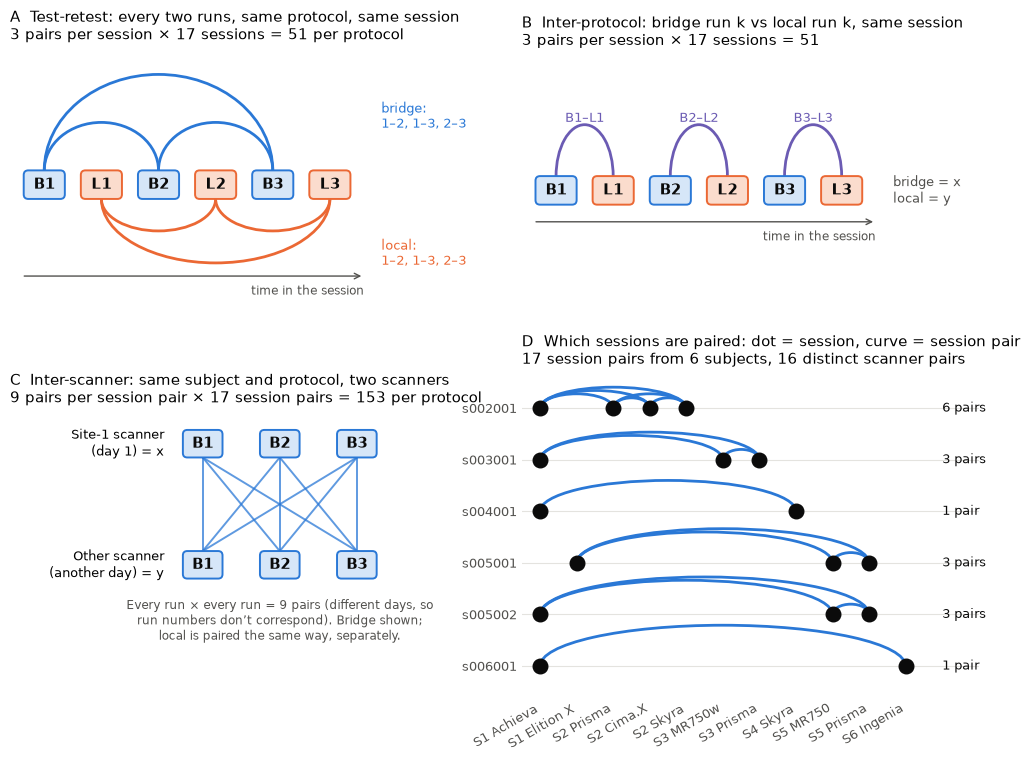

In [3]:
plan = pd.DataFrame(emtp.comparison_plan(acq), columns=['comparison', 'x', 'y'])
plan['protocol'] = plan.x.map(acq.set_index('acquisition').protocol)
per_protocol = plan[plan.protocol == 'bridge'].comparison.value_counts()
plots.pair_design(acq, name='pairs_design', counts={
    'sessions': acq.groupby(['subject', 'scanner']).ngroups,
    'test_retest': per_protocol['test_retest'], 'inter_scanner': per_protocol['inter_scanner'],
    'inter_protocol': (plan.comparison == 'inter_protocol').sum(),
    'session_pairs': per_protocol['inter_scanner'] // 9,
    'scanner_pairs': restrict(fits.a, comparison='inter_scanner').index.get_level_values('scanner_pair').nunique()})

Example: s005001, site-1 Elition, bridge, ROMEO + V-SHARP + MEDI.

run 2 vs 1: n = 18, a = 0.955, b = 4.8 ppb, LoA ±15.4, line-corrected ±14.7 ppb
run 3 vs 2: n = 18, a = 0.959, b = -5.3 ppb, LoA ±17.5, line-corrected ±16.9 ppb


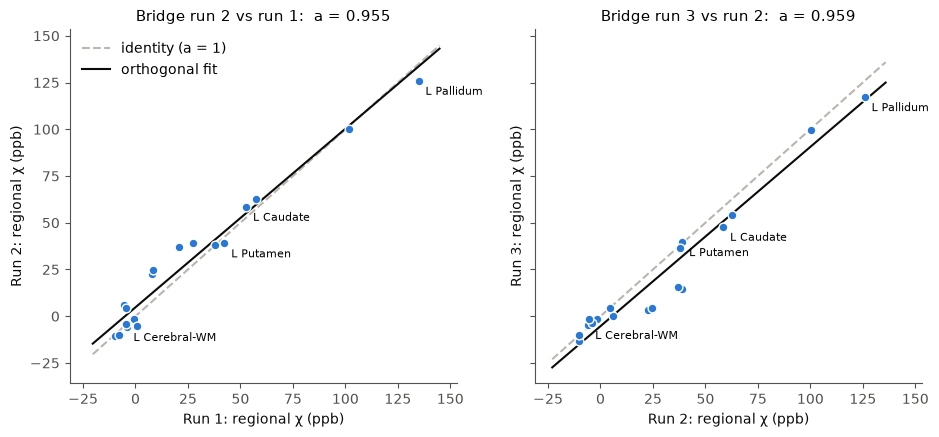

In [4]:
session = restrict(chi_lab, pipeline='romeo-qsmrs+vsharp-qsmrs+medi-qsmrs', subject='s005001', scanner='site1-elition', protocol='bridge')
run = {k: by(session, 'run')[f'run{k}'].droplevel(['pipeline', 'subject', 'scanner', 'protocol']) for k in (1, 2, 3)}
panels = []
for i, j in ((1, 2), (2, 3)):
    regions = run[i].index.intersection(run[j].index)
    x, y = run[i][regions], run[j][regions]
    a, b = fit_line(x, y)
    print(f'run {j} vs {i}: n = {len(regions)}, a = {a:.3f}, b = {b:.1f} ppb, '
          f'LoA ±{1.96 * sd(y - x):.1f}, line-corrected ±{1.96 * sd(y - (a * x + b)):.1f} ppb')
    panels.append((f'Bridge run {j} vs run {i}:  a = {a:.3f}', f'Run {i}: regional χ (ppb)', f'Run {j}: regional χ (ppb)', x, y, (a, b)))
plots.example_fit(panels, name='example_fit')

## F1 · Test-retest: median |a − 1| vs SD of a (#2)

Per pipeline, over its test-retest pairs (3 per session): $m = \operatorname{median}_k |a_k - 1|$, $s = \operatorname{SD}_k\, a_k$, $d = \operatorname{mean}_k (a_k - 1)$.

,median m,median s,median d,m / s
protocol,,,,
bridge,2.28,3.49,-0.20,0.65
local,1.81,3.21,0.11,0.56


- Mean a − 1: -0.2% (bridge), +0.1% (local).
- m / s: 0.65 (bridge), 0.56 (local); 0.674 is expected for normal a − 1 centred on 0 (median |a − 1| = 0.674 σ).
- Median |a − 1| stays primary (D1), with SD of a as secondary.
- The 3 pairs per session share scans, so one odd run affects two of them (see F7).

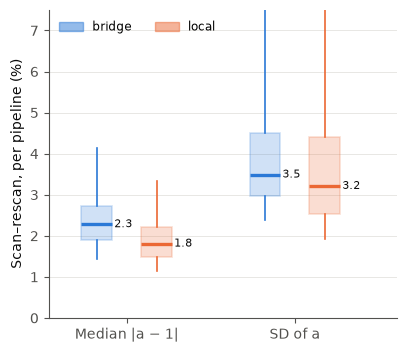

In [5]:
a_T = 100 * restrict(fits.a, comparison='test_retest')
m = median(abs(a_T - 100), each=('pipeline', 'protocol'))
s = sd(a_T, each=('pipeline', 'protocol'))
d = mean(a_T - 100, each=('pipeline', 'protocol'))
display(pd.DataFrame({'median m': median(m, each='protocol'), 'median s': median(s, each='protocol'),
                      'median d': median(d, each='protocol'), 'm / s': median(m, each='protocol') / median(s, each='protocol')}).round(2))
plots.boxes({'Median |a − 1|': by(m, 'protocol'), 'SD of a': by(s, 'protocol')},
            ylabel='Scan–rescan, per pipeline (%)', ylim=(0, 7.5), name='fig1_sd_of_a');
md, ms = median(d, each='protocol'), median(m, each='protocol') / median(s, each='protocol')
note(f"Mean a − 1: {md['bridge']:+.1f}% (bridge), {md['local']:+.1f}% (local).",
     f"m / s: {ms['bridge']:.2f} (bridge), {ms['local']:.2f} (local); 0.674 is expected for normal a − 1 centred on 0 (median |a − 1| = 0.674 σ).",
     "Median |a − 1| stays primary (D1), with SD of a as secondary.",
     "The 3 pairs per session share scans, so one odd run affects two of them (see F7).")

## F2 · Inter-scanner, by scanner pair (#2, #7)

$M_{p,\pi} = \operatorname{median}_{k \in \mathcal I_\pi} |a_k - 1|$ over all its inter-scanner pairs; $M_{p,\pi,c}$ the same within scanner pair $c$ (9 run combinations per subject); spread across pairs $\mathrm{IQR}_c\, M_{p,\pi,c}$.

In [6]:
dev_I = 100 * abs(restrict(fits.a, comparison='inter_scanner') - 1)
M = median(dev_I, each=('pipeline', 'protocol'))
M_c = median(dev_I, each=('pipeline', 'protocol', 'scanner_pair'))
spread_c = iqr(M_c, each=('pipeline', 'protocol'))
display(pd.DataFrame({'median': median(M, each='protocol'), 'p75': quantile(M, .75, each='protocol'),
                      'p95': quantile(M, .95, each='protocol'), 'IQR across pairs': median(spread_c, each='protocol')}).round(2))
median(M_c, each=('scanner_pair', 'protocol')).unstack().round(2)

,median,p75,p95,IQR across pairs
protocol,,,,
bridge,5.26,8.38,21.13,6.37
local,7.21,10.81,21.70,7.86


protocol,bridge,local
scanner_pair,,
site1-achieva – site2-cimax,4.26,8.27
site1-achieva – site2-prisma,4.05,7.69
site1-achieva – site2-skyra,3.96,8.77
site1-achieva – site3-mr750w,5.89,6.09
site1-achieva – site3-prisma,7.68,7.96
site1-achieva – site4-skyra,10.16,10.39
site1-achieva – site5-mr750,10.83,7.43
site1-achieva – site5-prisma,10.19,8.41
site1-achieva – site6-ingenia,4.58,4.90


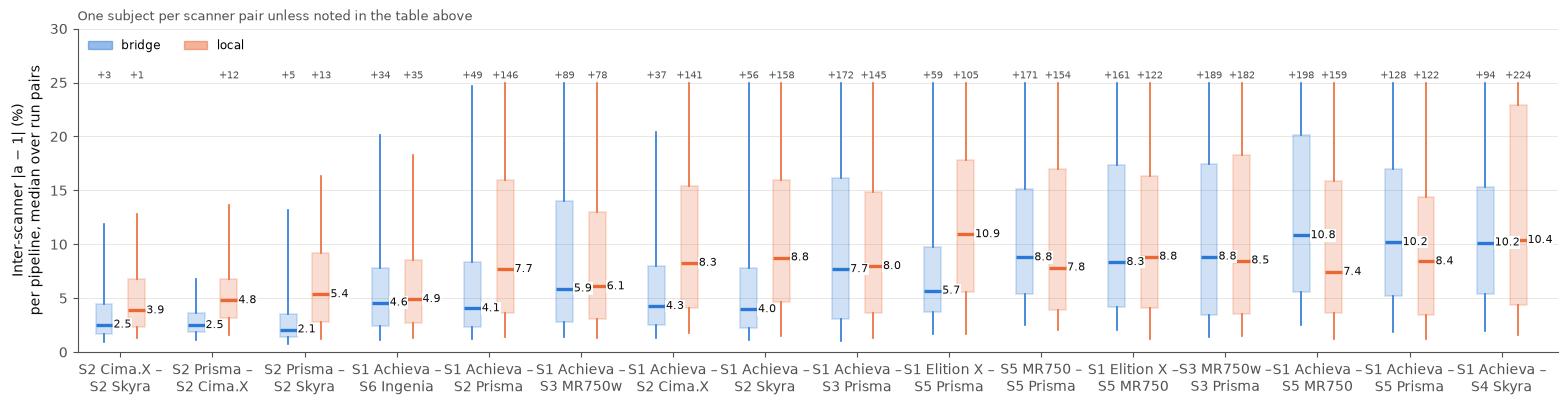

In [7]:
order = mean(median(M_c, each=('scanner_pair', 'protocol')), each='scanner_pair').sort_values().index
plots.boxes({plots.scanner_pair(c): by(restrict(M_c, scanner_pair=c), 'protocol') for c in order},
            ylabel='Inter-scanner |a − 1| (%)\nper pipeline, median over run pairs', ylim=(0, 30), cap=25, figsize=(max(11, 1.1 * len(order) + 1.5), 4.2),
            title='One subject per scanner pair unless noted in the table above', name='fig2_scanner_pairs');

In [8]:
# same site vs different sites (#7); by vendor (#8) in results/followup/inter_scanner_by_vendor.csv
same_site = median(median(dev_I, each=('pipeline', 'protocol', 'same_site')), each=('same_site', 'protocol')).unstack()
print('same-site scanner pairs:', sorted({c for c in restrict(dev_I, same_site=True).index.get_level_values('scanner_pair')}))
same_site.round(2)

same-site scanner pairs: ['site2-cimax – site2-skyra', 'site2-prisma – site2-cimax', 'site2-prisma – site2-skyra', 'site3-mr750w – site3-prisma', 'site5-mr750 – site5-prisma']


protocol,bridge,local
same_site,,
False,5.89,7.72
True,4.14,5.93


In [9]:
M_bridge, M_local = by(M, 'protocol').values()
print(f"pipelines with bridge < local: {((M_bridge - M_local).dropna() < 0).mean():.2f}")
b = json.load(open('results/followup/followup.json'))['bootstrap_over_subjects']   # analysis/followup.py, 500 resamples of subjects
pd.DataFrame({k.replace('inter_scanner_', ''): {'estimate': b[k]['estimate'], 'ci95 low': b[k]['ci95'][0], 'ci95 high': b[k]['ci95'][1]}
              for k in ('inter_scanner_median_bridge_minus_local_pct', 'inter_scanner_p75_bridge_minus_local_pct',
                        'inter_scanner_p95_bridge_minus_local_pct')}).T

pipelines with bridge < local: 0.73


,estimate,ci95 low,ci95 high
median_bridge_minus_local_pct,-1.17,-2.07,0.42
p75_bridge_minus_local_pct,-2.44,-4.05,1.06
p95_bridge_minus_local_pct,-0.57,-7.32,5.93


In [10]:
sc_iqr, med_M = median(spread_c, each='protocol'), median(M, each='protocol')
ci = {k: b[f'inter_scanner_{k}_bridge_minus_local_pct']['ci95'] for k in ('median', 'p75', 'p95')}
note(f"IQR across scanner pairs: {sc_iqr['bridge']:.1f}% (bridge), {sc_iqr['local']:.1f}% (local), against median deviations of "
     f"{med_M['bridge']:.1f}% and {med_M['local']:.1f}%. Most scanner pairs have one subject, so scanner and subject are confounded.",
     f"Same site vs different sites (median |a − 1|, bridge / local): {same_site.loc[True, 'bridge']:.1f} / {same_site.loc[True, 'local']:.1f}% "
     f"vs {same_site.loc[False, 'bridge']:.1f} / {same_site.loc[False, 'local']:.1f}%.",
     f"Pipelines with bridge < local: {((M_bridge - M_local).dropna() < 0).mean():.0%}. Bootstrap 95% CI of bridge − local: median "
     f"{ci['median'][0]:+.2f} to {ci['median'][1]:+.2f}, p75 {ci['p75'][0]:+.2f} to {ci['p75'][1]:+.2f}, p95 {ci['p95'][0]:+.2f} to {ci['p95'][1]:+.2f} percentage points.")

- IQR across scanner pairs: 6.4% (bridge), 7.9% (local), against median deviations of 5.3% and 7.2%. Most scanner pairs have one subject, so scanner and subject are confounded.
- Same site vs different sites (median |a − 1|, bridge / local): 4.1 / 5.9% vs 5.9 / 7.7%.
- Pipelines with bridge < local: 73%. Bootstrap 95% CI of bridge − local: median -2.07 to +0.42, p75 -4.05 to +1.06, p95 -7.32 to +5.93 percentage points.

## F3 · LoA before and after removing each pair's line (#3)

$L_{p,\kappa,\pi} = \operatorname{median}_k \mathrm{LoA}_k$ and the same for the line-corrected LoA. Share of variance explained by the line: $1 - (L^{\text{line}}/L)^2$.

In [11]:
L = median(fits.loa, each=('pipeline', 'comparison', 'protocol'))
L_line = median(fits.loa_corrected, each=('pipeline', 'comparison', 'protocol'))
table = pd.DataFrame({'L (±ppb)': median(L, each=('comparison', 'protocol')),
                      'L_line (±ppb)': median(L_line, each=('comparison', 'protocol')),
                      'variance explained (%)': median(100 * (1 - (L_line / L) ** 2), each=('comparison', 'protocol'))})
table['narrower (%)'] = 100 * (1 - table['L_line (±ppb)'] / table['L (±ppb)'])
restrict(table, comparison=['test_retest', 'inter_scanner']).round(1)

L (±ppb)  L_line (±ppb)  variance explained (%)  \
comparison    protocol                                                    
inter_scanner bridge        17.5           16.3                    12.3   
              local         18.8           17.3                    20.0   
test_retest   bridge         8.4            7.9                    11.6   
              local          6.5            6.1                    11.4   

                        narrower (%)  
comparison    protocol                
inter_scanner bridge             6.7  
              local              7.8  
test_retest   bridge             5.9  
              local              5.1

- Removing the line narrows the LoA by 5–8% (it explains 11–20% of the variance).
- A 6% scale moves the pallidum (~150 ppb) by ~9 ppb, but barely moves the many regions near 0.
- In-sample (2 parameters fitted on up to 25 points), so this is an upper bound.
- LoA uses ddof = 1; QSM-CI uses ddof = 0 (~2.5% narrower).

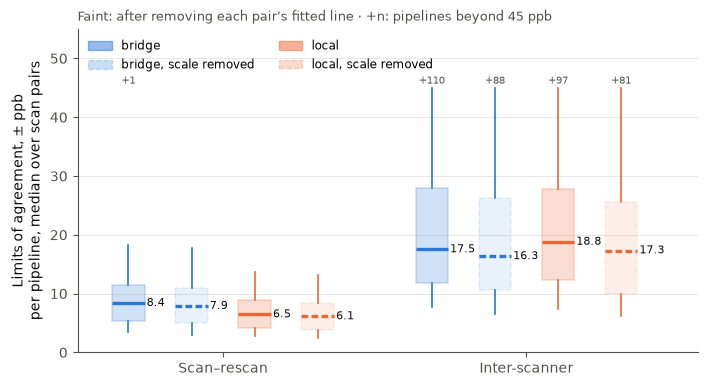

In [12]:
def loa_boxes(κ):
    return {f'{π}{label}': restrict(X, comparison=κ, protocol=π)
            for π in ('bridge', 'local') for label, X in (('', L), (', scale removed', L_line))}

plots.boxes({'Scan–rescan': loa_boxes('test_retest'), 'Inter-scanner': loa_boxes('inter_scanner')},
            ylabel='Limits of agreement, ± ppb\nper pipeline, median over scan pairs', ylim=(0, 55), cap=45, figsize=(8, 4.2),
            title='Faint: after removing each pair’s fitted line · +n: pipelines beyond 45 ppb', name='fig3_loa_corrected');
t = restrict(table, comparison=['test_retest', 'inter_scanner'])
note(f"Removing the line narrows the LoA by {t['narrower (%)'].min():.0f}–{t['narrower (%)'].max():.0f}% (it explains "
     f"{t['variance explained (%)'].min():.0f}–{t['variance explained (%)'].max():.0f}% of the variance).",
     "A 6% scale moves the pallidum (~150 ppb) by ~9 ppb, but barely moves the many regions near 0.",
     "In-sample (2 parameters fitted on up to 25 points), so this is an upper bound.",
     "LoA uses ddof = 1; QSM-CI uses ddof = 0 (~2.5% narrower).")

## F4 · Sources of variability; protocol bar corrected for scale (#4)

With $\bar\chi$ the run average:

| Bar | |
|---|---|
| Rescan | $\operatorname{median}_p \operatorname{median}_{s,c} \operatorname{SD}_r\, \chi_{p,s,c,\pi,r}$ |
| Protocol | $\operatorname{median}_p \operatorname{median}_{s,c} \operatorname{SD}_\pi\, \bar\chi_{p,s,c,\pi}$ |
| Scanner | $\operatorname{median}_p \operatorname{median}_{s} \operatorname{SD}_c\, \bar\chi_{p,s,c,\pi}$ |
| Pipeline | $\operatorname{median}_{s,c} \operatorname{SD}_p\, \bar\chi_{p,s,c,\pi}$ |
| Between subjects | $\operatorname{median}_p \operatorname{SD}_s\, \bar\chi_{p,s,c_0,\pi}$ ($c_0$ = site-1 Achieva) |

Correction: per pipeline and scanner, $(a, b)$ = the median of the inter-protocol fits; local $\chi \to (\chi - b)/a$. This is in-sample.

In [13]:
def sources(chi):
    """Fig. 4 bars (SD, ppb) of one region, per protocol; protocol bar under 'both'."""
    chibar = mean(chi, each=('pipeline', 'subject', 'scanner', 'protocol'))
    bars = pd.DataFrame({
        'rescan':           median(median(sd(chi, each=('pipeline', 'subject', 'scanner', 'protocol')), each=('pipeline', 'protocol')), each='protocol'),
        'scanner':          median(median(sd(chibar, each=('pipeline', 'subject', 'protocol')), each=('pipeline', 'protocol')), each='protocol'),
        'pipeline':         median(sd(chibar, each=('subject', 'scanner', 'protocol')), each='protocol'),
        'between subjects': median(sd(restrict(chibar, scanner='site1-achieva'), each=('pipeline', 'protocol')), each='protocol'),
    }).T
    bars.loc['protocol', 'both'] = median(median(sd(chibar, each=('pipeline', 'subject', 'scanner')), each='pipeline'))
    return bars


bars = {R: sources(chi[R]) for R in chi}
line_pc = median(restrict(fits[['a', 'b']], comparison='inter_protocol'), each=('pipeline', 'scanner_x')).rename_axis(['pipeline', 'scanner'])
protocol_after = {R: sources(pd.concat([restrict(x, protocol='bridge'), undo_line(restrict(x, protocol='local'), line_pc)])).loc['protocol', 'both']
                  for R, x in chi.items()}
print(f"local-vs-bridge a: median {median(line_pc.a):.3f}, IQR {quantile(line_pc.a, .25):.3f}–{quantile(line_pc.a, .75):.3f}")
print('protocol bar after removing the line:', {R: round(float(v), 1) for R, v in protocol_after.items()})
pd.concat(bars, axis=1).round(1)

local-vs-bridge a: median 0.987, IQR 0.946–1.031
protocol bar after removing the line: {'Caudate': 2.0, 'Pallidum': 2.1}


Caudate            Pallidum           
protocol          bridge local both   bridge local both
rescan               1.6   1.2  NaN      2.6   2.2  NaN
scanner              3.9   4.7  NaN      6.9   8.4  NaN
pipeline            19.1  19.9  NaN     34.5  37.3  NaN
between subjects    13.7  12.9  NaN     29.6  27.0  NaN
protocol             NaN   NaN  2.5      NaN   NaN  3.7

- The protocol bar is the SD of two values, i.e. |bridge − local| / √2.
- Removing the line: caudate 2.5 → 2.0 ppb (rescan 1.6 / 1.2), pallidum 3.7 → 2.1 ppb (rescan 2.6 / 2.2). Best case only; F6 is the out-of-sample version.
- Bars stay uncorrected in the figure (D4).

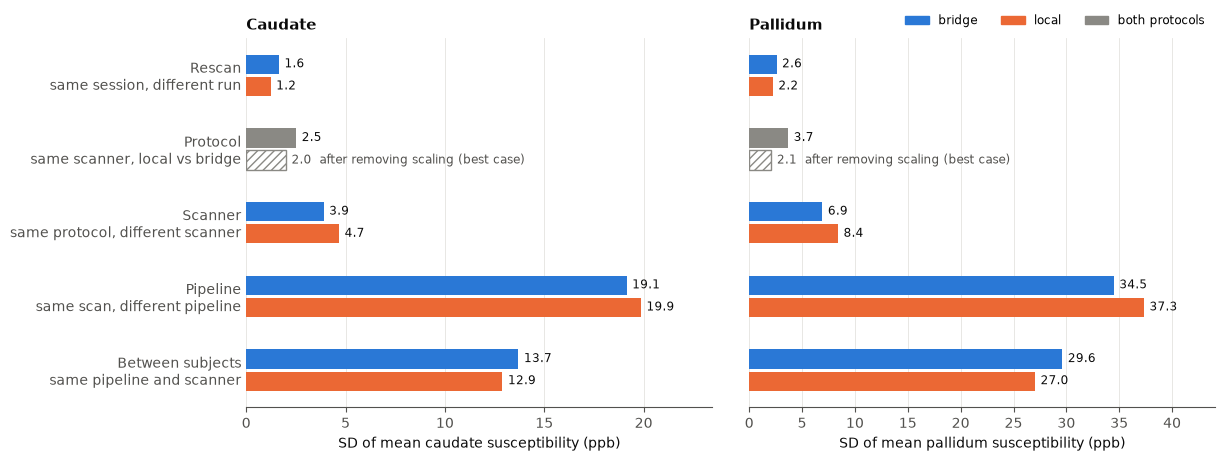

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'wspace': 0.08})
for ax, (R, B) in zip(axs, bars.items()):
    plots.hbars({'Rescan\nsame session, different run':         {'bridge': B.bridge['rescan'], 'local': B.local['rescan']},
                 'Protocol\nsame scanner, local vs bridge':      {'both protocols': B.both['protocol'], 'after removing scaling (best case)': protocol_after[R]},
                 'Scanner\nsame protocol, different scanner':    {'bridge': B.bridge['scanner'], 'local': B.local['scanner']},
                 'Pipeline\nsame scan, different pipeline':      {'bridge': B.bridge['pipeline'], 'local': B.local['pipeline']},
                 'Between subjects\nsame pipeline and scanner':  {'bridge': B.bridge['between subjects'], 'local': B.local['between subjects']}},
                xlabel=f'SD of mean {R.lower()} susceptibility (ppb)', ax=ax, title=R, legend=(R == 'Pallidum'))
axs[1].set_yticklabels([])
plots.save(fig, 'fig4_protocol_corrected')
note("The protocol bar is the SD of two values, i.e. |bridge − local| / √2.",
     'Removing the line: ' + ', '.join(f"{R.lower()} {bars[R].both['protocol']:.1f} → {protocol_after[R]:.1f} ppb "
                                        f"(rescan {bars[R].bridge['rescan']:.1f} / {bars[R].local['rescan']:.1f})" for R in bars)
     + '. Best case only; F6 is the out-of-sample version.',
     'Bars stay uncorrected in the figure (D4).')

## F5 · One conversion line per pipeline (#6)

Consensus $\tilde\chi_{t,i} = \operatorname{median}_p \chi_{p,t,i}$. Fit $\chi_{p,t,\cdot} \approx a_{p,t}\tilde\chi_{t,\cdot} + b_{p,t}$ for each scan $t$. Each pipeline's line $(a_p, b_p)$ is the median over the site-1 Achieva bridge scans only, then applied to all its scans. The pipeline SD is evaluated on the held-out scans.

In [15]:
consensus = median(chi_lab, each=('subject', 'scanner', 'protocol', 'run', 'region'))
line_pt = fit_to_reference(chi_lab, consensus)
line_p = median(restrict(line_pt, scanner='site1-achieva', protocol='bridge'), each='pipeline')

held_out = lambda x: exclude(x, scanner='site1-achieva', protocol='bridge')
pipeline_bar = {R: {'as is': sources(held_out(x)).loc['pipeline'], 'one line': sources(held_out(undo_line(x, line_p))).loc['pipeline']}
                for R, x in chi.items()}
pd.DataFrame({(R, k): v for R, d in pipeline_bar.items() for k, v in d.items()}).round(1)

Caudate          Pallidum         
           as is one line    as is one line
protocol                                   
bridge      19.2     16.2     34.2     26.9
local       19.9     12.4     37.3     21.1
both         NaN      NaN      NaN      NaN

In [16]:
ln_a = np.log(line_pt.a.clip(lower=1e-3))
ln_a_bar = mean(ln_a, each=('pipeline', 'subject', 'scanner', 'protocol'))
within = pd.Series({
    'runs':      median(median(sd(ln_a, each=('pipeline', 'subject', 'scanner', 'protocol')), each='pipeline')),
    'protocols': median(median(sd(ln_a_bar, each=('pipeline', 'subject', 'scanner')), each='pipeline')),
    'scanners':  median(median(sd(ln_a_bar, each=('pipeline', 'subject', 'protocol')), each='pipeline')),
    'subjects':  median(median(sd(restrict(ln_a_bar, scanner='site1-achieva'), each=('pipeline', 'protocol')), each='pipeline'))})
a_p = median(line_pt.a, each='pipeline')
print('SD of a within a pipeline (%):', (100 * within).round(1).to_dict())
print(f'between pipelines: IQR of a_p {quantile(a_p, .25):.2f}–{quantile(a_p, .75):.2f}')

SD of a within a pipeline (%): {'runs': 1.4, 'protocols': 2.9, 'scanners': 5.6, 'subjects': 6.0}
between pipelines: IQR of a_p 0.88–1.21


- Pallidum pipeline SD on the held-out scans: bridge 34 → 27 ppb, local 37 → 21 ppb (scanner 6.9 / 8.4, protocol 3.7).
- Within a pipeline, SD of a: runs 1.4%, protocols 2.9%, scanners 5.6%, subjects 6.0%; between pipelines a_p spans 0.88–1.21 (IQR).
- Results for good pipelines only (#6, D9): results/followup/followup.json, issue_6_pipeline_conversion_good.

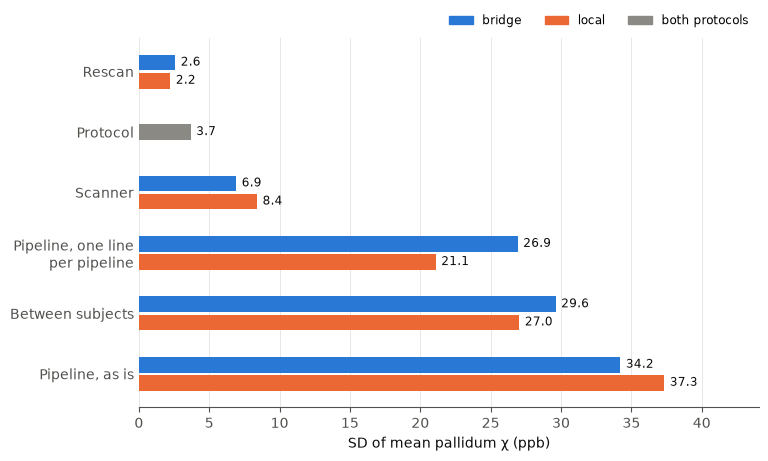

In [17]:
B, conv = bars['Pallidum'], pipeline_bar['Pallidum']
plots.hbars({'Rescan':                           {'bridge': B.bridge['rescan'], 'local': B.local['rescan']},
             'Protocol':                         {'both protocols': B.both['protocol']},
             'Scanner':                          {'bridge': B.bridge['scanner'], 'local': B.local['scanner']},
             'Pipeline, one line\nper pipeline': {'bridge': conv['one line'].bridge, 'local': conv['one line'].local},
             'Between subjects':                 {'bridge': B.bridge['between subjects'], 'local': B.local['between subjects']},
             'Pipeline, as is':                  {'bridge': conv['as is'].bridge, 'local': conv['as is'].local}},
            xlabel='SD of mean pallidum χ (ppb)', name='fig5_pipeline_conversion');
asis, one = conv['as is'], conv['one line']
note(f"Pallidum pipeline SD on the held-out scans: bridge {asis.bridge:.0f} → {one.bridge:.0f} ppb, local {asis.local:.0f} → {one.local:.0f} ppb "
     f"(scanner {B.bridge['scanner']:.1f} / {B.local['scanner']:.1f}, protocol {B.both['protocol']:.1f}).",
     'Within a pipeline, SD of a: ' + ', '.join(f'{k} {100 * v:.1f}%' for k, v in within.items())
     + f"; between pipelines a_p spans {quantile(a_p, .25):.2f}–{quantile(a_p, .75):.2f} (IQR).",
     "Results for good pipelines only (#6, D9): results/followup/followup.json, issue_6_pipeline_conversion_good.")

## F6 · Local-to-bridge calibration, leave one subject out (#5)

On the scanners with ≥ 2 subjects: subject line $(a, b)_{p,c,s}$ = the median over its 3 inter-protocol fits; learned line $(\hat a, \hat b)_{p,c,s} = \operatorname{median}_{s' \ne s}(a, b)_{p,c,s'}$; local $\chi \to (\chi - \hat b)/\hat a$, refit against bridge, $|a' - 1|$. Compared with no correction and with the subject's own line (in-sample).

In [18]:
scanners = [c for c, n in acq.groupby('scanner').subject.nunique().items() if n >= 2]
fits_P = restrict(fits[['a', 'b']], comparison='inter_protocol', scanner_x=scanners)
line_s = median(fits_P, each=('pipeline', 'scanner_x', 'subject'))
line_loo = leave_one_out(line_s, over='subject')
pairs = having(fits_P, line_loo)
dev_P = pd.DataFrame({'no correction': 100 * abs(pairs.a - 1),
                      'other subjects': 100 * refit_local_into_bridge(chi_lab, pairs, line_loo),
                      'same subject': 100 * refit_local_into_bridge(chi_lab, pairs, line_s)})
per_pipeline = median(dev_P, each='pipeline')
print('SD of a_(p,c,s) over subjects (%):', (100 * median(sd(line_s.a, each=('pipeline', 'scanner_x')), each='scanner_x')).round(1).to_dict())
median(per_pipeline).round(2).to_frame('median over pipelines (%)').T

SD of a_(p,c,s) over subjects (%): {'site1-achieva': 4.3, 'site5-mr750': 3.3, 'site5-prisma': 4.9}


,no correction,other subjects,same subject
median over pipelines (%),4.42,4.66,1.06


- Local vs bridge |a − 1|: no correction 4.4%, learned on the other subjects 4.7%, same subject (in-sample, circular) 1.1%.
- SD of the local-to-bridge slope over subjects: site1-achieva 4.3%, site5-mr750 3.3%, site5-prisma 4.9%; median a 0.986.
- Scanners with 2+ subjects: site1-achieva (5), site5-mr750 (2), site5-prisma (2).

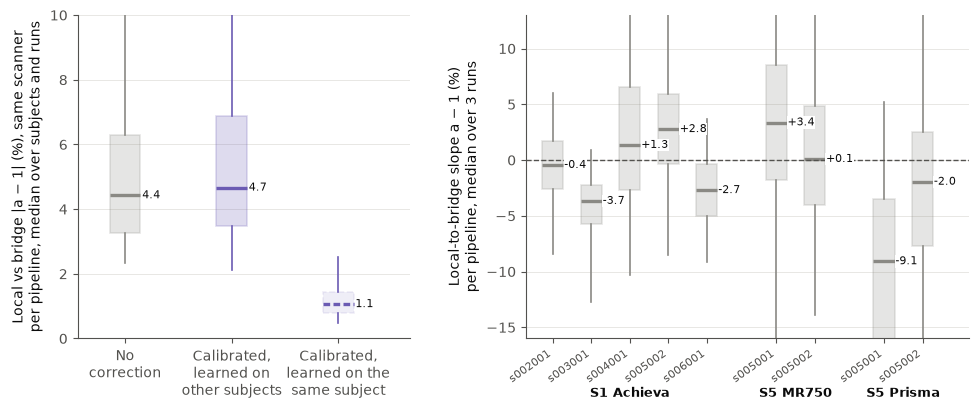

In [19]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={'width_ratios': [1.2, 1.6], 'wspace': 0.3})
plots.boxes({'No\ncorrection':                            {'no correction': per_pipeline['no correction']},
             'Calibrated,\nlearned on\nother subjects':   {'other subjects': per_pipeline['other subjects']},
             'Calibrated,\nlearned on the\nsame subject': {'same subject': per_pipeline['same subject']}},
            ylabel='Local vs bridge |a − 1| (%), same scanner\nper pipeline, median over subjects and runs', ax=left, ylim=(0, 10),
            colors={'no correction': plots.GREY, 'other subjects': plots.PURPLE, 'same subject': plots.PURPLE},
            faint={'same subject'}, legend=False)
plots.subject_boxes(100 * (median(fits_P.a, each=('scanner_x', 'subject', 'pipeline')) - 1),
                    ylabel='Local-to-bridge slope a − 1 (%)\nper pipeline, median over 3 runs', ax=right, ylim=(-16, 13))
plots.save(fig, 'fig6_calibration')
mp = median(per_pipeline)
note(f"Local vs bridge |a − 1|: no correction {mp['no correction']:.1f}%, learned on the other subjects {mp['other subjects']:.1f}%, "
     f"same subject (in-sample, circular) {mp['same subject']:.1f}%.",
     'SD of the local-to-bridge slope over subjects: ' + ', '.join(f'{c} {100 * v:.1f}%' for c, v in median(sd(line_s.a, each=('pipeline', 'scanner_x')), each='scanner_x').items())
     + f"; median a {median(fits_P.a):.3f}.",
     'Scanners with 2+ subjects: ' + ', '.join(f'{c} ({n})' for c, n in acq.groupby('scanner').subject.nunique().items() if n >= 2) + '.')

## F7 · Bridge run 1 (#10)

$r^{ij}$ = the median over pipelines of $|a - 1|$ for runs $i$ vs $j$, per session and protocol. Run 1 is odd if $r^{12} > r^{23}$ and $r^{13} > r^{23}$. Null: each of the 3 pairs is equally likely to be the best, so $p = 1/3$ per session.

In [20]:
r = median(100 * abs(restrict(fits.a, comparison='test_retest') - 1), each=('subject', 'scanner_x', 'protocol', 'run_x', 'run_y'))
r12, r13, r23 = (restrict(r, run_x=f'run{i}', run_y=f'run{j}').droplevel(['run_x', 'run_y']) for i, j in ((1, 2), (1, 3), (2, 3)))
run1_odd = (r12 > r23) & (r13 > r23)
odd = pd.DataFrame({'run 1 odd': total(run1_odd, each='protocol'), 'sessions': total(run1_odd > -1, each='protocol')})
odd['p (binomial, one-sided)'] = binom.sf(odd['run 1 odd'] - 1, odd.sessions, 1 / 3)
display(odd.round(4))
restrict(pd.DataFrame({'r12': r12, 'r13': r13, 'r23': r23, 'run 1 odd': run1_odd}), protocol='bridge').round(2)

,run 1 odd,sessions,"p (binomial, one-sided)"
protocol,,,
bridge,11,17,8.00e-03
local,5,17,7.19e-01


r12   r13   r23  run 1 odd
subject scanner_x     protocol                             
s002001 site1-achieva bridge    3.96  3.31  1.39       True
        site2-cimax   bridge    3.20  1.99  1.32       True
        site2-prisma  bridge    1.71  1.95  2.13      False
        site2-skyra   bridge    1.76  2.24  1.52       True
s003001 site1-achieva bridge    2.11  1.71  1.58       True
        site3-mr750w  bridge    2.93  1.99  3.39      False
        site3-prisma  bridge    2.26  2.31  1.95       True
s004001 site1-achieva bridge    3.44  3.02  1.51       True
        site4-skyra   bridge    2.27  4.63  2.26       True
s005001 site1-elition bridge    5.87  6.34  1.79       True
        site5-mr750   bridge    2.39  1.92  1.95      False
        site5-prisma  bridge    2.05  3.12  1.45       True
s005002 site1-achieva bridge    2.09  3.24  3.79      False
        site5-mr750   bridge    2.55  2.70  4.59      False
        site5-prisma  bridge    2.45  1.73  1.79      False
s006001 site1-achieva bridge    2.07  1.74  1.30       True
        site6-ingenia bridge    1.31  1.97  1.13       True

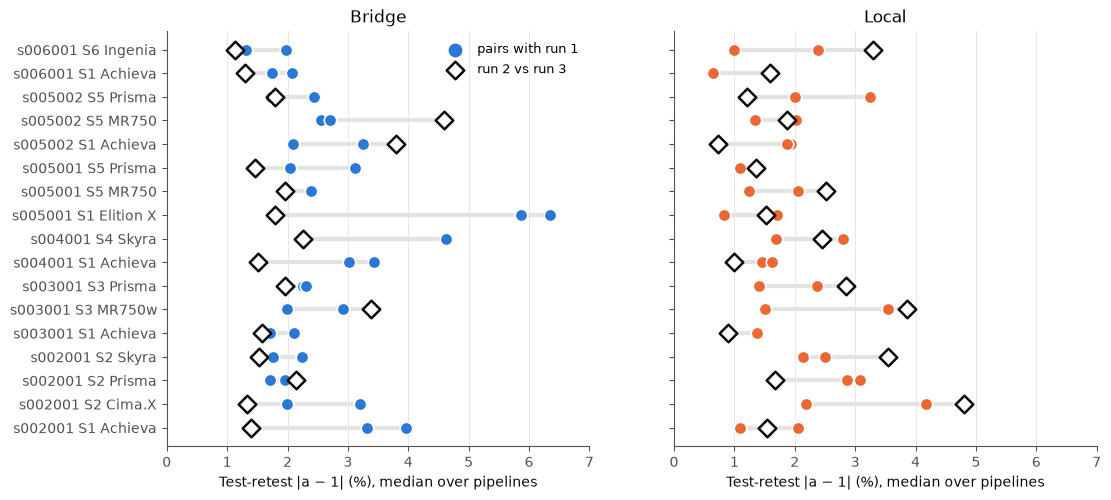

In [21]:
plots.run_pairs(r12, r13, r23, name='fig7_run_pairs_sessions')

In [22]:
note(*(f"{π}: run 1 odd in {int(odd.loc[π, 'run 1 odd'])} of {int(odd.loc[π, 'sessions'])} sessions "
       f"(p = {odd.loc[π, 'p (binomial, one-sided)']:.3f})" for π in odd.index),
     'The p-value treats sessions as independent, which they are not quite (a subject contributes several sessions).')

- bridge: run 1 odd in 11 of 17 sessions (p = 0.008)
- local: run 1 odd in 5 of 17 sessions (p = 0.719)
- The p-value treats sessions as independent, which they are not quite (a subject contributes several sessions).

- Ruled out on the first 12 sessions: within-session motion (~0.5°), ghosting, edge sharpness, and field drift between runs (`data/`; these measurements cover those sessions only).
- Open: pillow settling (3–5 min), scanner warm-up (s002001 was the first scan of the day; s004001/s005001 came after a gap of more than 30 min), physiological settling.
- The first scan and the bridge protocol are confounded by the fixed run order. Counterbalance it or add a dummy scan (D6).

## F8 · With and without run 1 (#10)

Without run 1: test-retest keeps only run 2 vs 3 (1 pair per session); inter-scanner keeps 4 of 9 run combinations.

,test_retest,inter_scanner
bridge,2.28,5.26
"bridge, without run 1",1.87,5.24
local,1.81,7.21
"local, without run 1",1.83,7.42


- test-retest: bridge 2.3% → 1.9%, local 1.8% → 1.8%
- inter-scanner: bridge 5.3% → 5.2%, local 7.2% → 7.4%

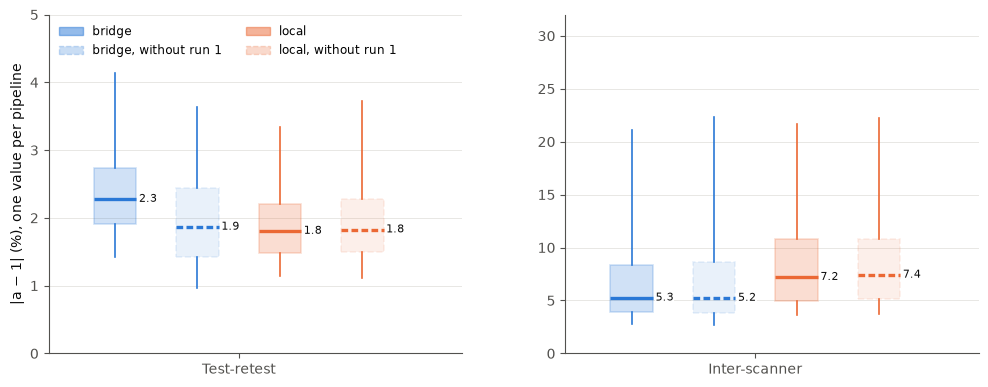

In [23]:
def per_pipeline_dev(comparison, **only):
    return median(100 * abs(restrict(fits.a, comparison=comparison, **only) - 1), each=('pipeline', 'protocol'))


groups = {κ: {f'{π}{label}': restrict(per_pipeline_dev(κ, **only), protocol=π)
              for π in ('bridge', 'local') for label, only in (('', {}), (', without run 1', {'with_run1': False}))}
          for κ in ('test_retest', 'inter_scanner')}
display(pd.DataFrame({κ: {k: median(v) for k, v in g.items()} for κ, g in groups.items()}).round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={'wspace': 0.25})
plots.boxes({'Test-retest': groups['test_retest']}, ylabel='|a − 1| (%), one value per pipeline', ax=axs[0], ylim=(0, 5))
plots.boxes({'Inter-scanner': groups['inter_scanner']}, ylabel='', ax=axs[1], ylim=(0, 32), legend=False)
plots.save(fig, 'fig8_without_run1')
g = {κ: {k: median(v) for k, v in grp.items()} for κ, grp in groups.items()}
note(*(f"{κ.replace('_', '-')}: " + ', '.join(f"{π} {g[κ][π]:.1f}% → {g[κ][π + ', without run 1']:.1f}%" for π in ('bridge', 'local'))
       for κ in g))

## Caveats

- The effective sample size is subjects and sessions, not pipelines × pairs.
- Scanner and subject are confounded: most scanner pairs have one subject, and the two site-1 scanners share none.
- Head angle to B0 changes 2.5–15° between the first 12 sessions (largest in the GE sessions), confounded with scanner (`data/head_pose.csv`).
- All pipelines are included, so the tails reflect poor pipelines; parity and other variants are separate pipelines.
- Regions are per hemisphere and include cortex, WM and cerebellum; the slope is dominated by deep grey matter.